# Phase 1 · Classical machine learning

Given a premise about correlations and independence, predict whether a causal claim follows. This notebook walks through the corrected run using the published results. See the [Phase 1 guide](../docs/phase1/README.md) for the full training commands.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'run_phase1.py').is_file())
RESULTS = ROOT / 'results' / 'phase1'

## 1. Check the dataset

A label of 1 means the hypothesis follows from the premise. The positive class is smaller, so we use macro F1, which gives the two classes equal weight.

train: 38048 positive, 167686 negative
dev: 139 positive, 937 negative
test: 180 positive, 982 negative


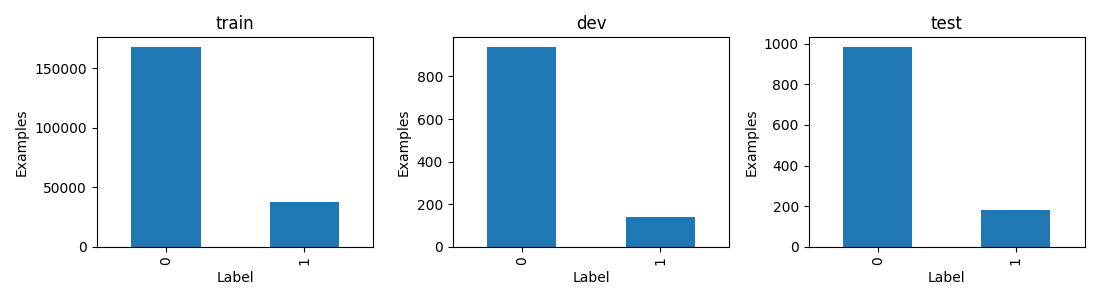

In [2]:
eda = json.loads((RESULTS / 'eda.json').read_text())
for split in ('train', 'dev', 'test'):
    counts = eda[split]['label_counts']
    print(f"{split}: {counts['1']} positive, {counts['0']} negative")
display(Image(filename=str(RESULTS / 'label_distribution.png')))

## 2. Compare the models

The models use [28 handcrafted features](../docs/phase1/featureDictionary.md) that describe the text and its variables. Logistic Regression, Linear SVM, and Random Forest are compared with a rule-based baseline. Development examples choose the model settings and graph threshold. The table reports results on the official test split.

# Corrected Phase 1 results

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| LinearSVM | 0.6945 | 0.5954 |
| LogisticRegression | 0.6799 | 0.5839 |
| RandomForest | 0.7117 | 0.6055 |
| RuleBased | 0.8184 | 0.4725 |
| CalibratedGraphModel | 0.7823 | 0.6357 |

6 separate premise graphs. Only direct claims create edges.
Other accepted claims remain in claims.json without invented direct edges.
Graph edge precision: not measured; Corr2Cause CSVs do not supply complete gold DAGs.
Three numerical queries validated against a specified synthetic network.
No observational CPDs or empirical intervention effects are estimated from Corr2Cause.
These are corrected rerun results. Historical submitted metrics remain in [the original Phase 1 submission](../../docs/phase1/original_results.csv).


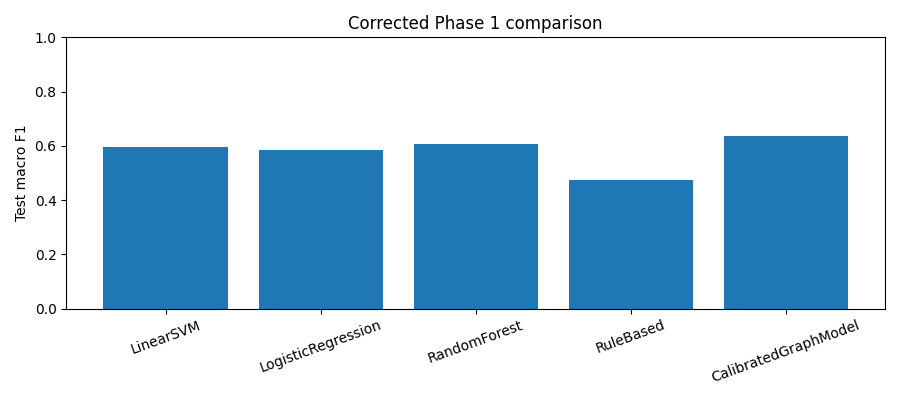

In [3]:
display(Markdown((RESULTS / 'RESULTS.md').read_text()))
display(Image(filename=str(RESULTS / 'model_comparison.png')))

## 3. Build a graph and check a query

A direct-cause claim above the score threshold can become a directed edge. Each premise has its own graph, and cycle removal keeps it acyclic. The query below uses a separate synthetic network with supplied probabilities and a known answer.

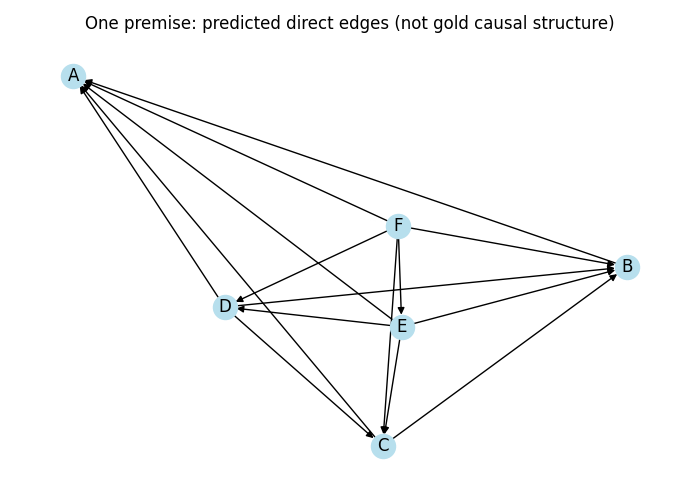

{'actual': 0.89, 'expected': 0.89, 'passed': True, 'query': 'P(Y=1 | X=1)'}
{'actual': 0.8500000000000001, 'expected': 0.85, 'passed': True, 'query': 'P(Y=1 | do(X=1))'}
{'actual': 0.25, 'expected': 0.25, 'passed': True, 'query': 'P(Y=1 | do(X=0))'}


In [4]:
display(Image(filename=str(RESULTS / 'example_graph.png')))
queries = json.loads((RESULTS / 'query_validation.json').read_text())
for query in queries['queries']:
    print(query)

## What Phase 2 adds

Phase 2 fine-tunes DistilBERT and compares it with a classical model trained on the same 2,100 examples. The full-data Phase 1 result provides context. See the [Phase 2 walkthrough](02_phase2_deep_learning.ipynb).